In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

***DATA Preprocessing***

In [3]:
df = sns.load_dataset('titanic')
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [4]:
print(sns.get_dataset_names())

['anagrams', 'anscombe', 'attention', 'brain_networks', 'car_crashes', 'diamonds', 'dots', 'dowjones', 'exercise', 'flights', 'fmri', 'geyser', 'glue', 'healthexp', 'iris', 'mpg', 'penguins', 'planets', 'seaice', 'taxis', 'tips', 'titanic']


In [5]:
df.shape

(891, 15)

In [6]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [7]:
df.head(2)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False


In [8]:
df.tail(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [9]:
df.sample(10)
# now we know y target its yes/no so its classification,

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
549,1,2,male,8.0,1,1,36.7500,S,Second,child,False,NaN,Southampton,yes,False
721,0,3,male,17.0,1,0,7.0542,S,Third,man,True,NaN,Southampton,no,False
257,1,1,female,30.0,0,0,86.5000,S,First,woman,False,B,Southampton,yes,True
385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True
559,1,3,female,36.0,1,0,17.4000,S,Third,woman,False,NaN,Southampton,yes,False
688,0,3,male,18.0,0,0,7.7958,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
363,0,3,male,35.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
553,1,3,male,22.0,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,yes,True
795,0,2,male,39.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [11]:
df.describe()
#statistical report of numerical data, we don't get if it is categorical data

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


statical representation of this describe() is 'Boxplt'

**Real Preprocessing**

In [12]:
df.isnull().sum()
#finding the missing values in the dataset in each column

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Finding the missing value percentages


In [13]:
df.isnull().sum()/len(df) * 100
# missing value of each cloumns divided by total number of rows

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

embark and embark town missing values are very minute, we can remove those missing rows
if the missing values are above 40% better option is to remove those columns completly
if the missing values are below 30% we can replace it

In [14]:
df.drop(columns='deck',inplace=True)
#or you can write df = df.drop(columns='deck')
# beacuse deck 77% missing value so we completly removed it from the data set 

In [15]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,Cherbourg,yes,True


**Treating missing values using measure of central tendency**

In [16]:
df["age"].fillna(df["age"].mean(), inplace=True)
# since age has less that 30% misssing values
# replacing the missing value(NaN) of age with its mean value
# writing code more bettter is: df["age"] = df["age"].fillna(df["age"].mean())

C:\Users\A\AppData\Local\Temp\ipykernel_11788\3457176553.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["age"].fillna(df["age"].mean(), inplace=True)


Important: This is called mean imputation in data preprocessing. It is a simple way to handle missing data, but the mean can be affected by outliers. For skewed age distributions, the median may be a better choice:
eg. if there are ages of infants 1 or 2 year and old like 100
df["age"] = df["age"].fillna(df["age"].median())

Use the mean when the data is reasonably symmetric and has no influential outliers.

Use the median when the data is skewed or contains extreme values.

Use a more advanced method when age depends on other variables, such as passenger class, sex, or family relationships.

In [17]:
# we can skewness
skewness = df["age"].skew()
print(skewness)

0.4344880940129925


Between −0.5 and +0.5	Approximately symmetric
Between −1 and −0.5, or +0.5 and +1	Moderately skewed
Below −1 or above +1	Highly skewed

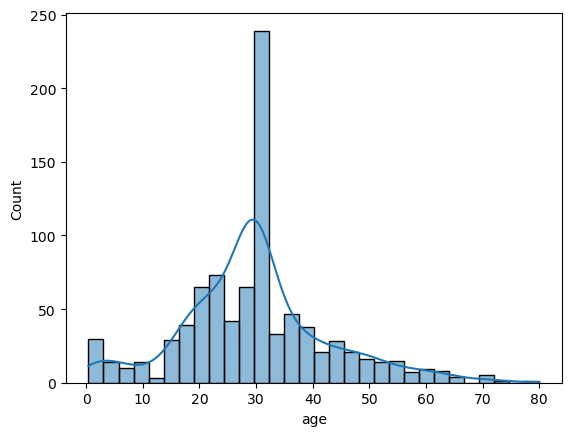

In [18]:
#Visualizing skewness
sns.histplot(data=df, x="age", kde=True)

plt.show()

In [19]:
skewness = df["age"].skew()

print("Skewness:", skewness)

if skewness > 0.5:
    print("Right-skewed")
elif skewness < -0.5:
    print("Left-skewed")
else:
    print("Approximately symmetric")

Skewness: 0.4344880940129925
Approximately symmetric


so there is no issue using mean for replacing,
its not neccessary to check skewness better to use median in first place, i just checked it out of curiosity

In [20]:
# checking are the missing value sin the age are replaced
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

In [21]:
embaTown = df['embark_town'].mode()[0] #.mode() finds the most frequently occurring value. [0] selects the first mode returned by Pandas.
df['embark_town'].fillna(embaTown, inplace=True) # It replaces every missing value (NaN) in embark_town with "Southampton".

C:\Users\A\AppData\Local\Temp\ipykernel_11788\1902010560.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embark_town'].fillna(embaTown, inplace=True) # It replaces every missing value (NaN) in embark_town with "Southampton".


why use mode ?
because embark_town is a categorical column containing text, not numerical measurements.

embaTown = df['embark_town'].mode()[0]

df['embark_town'] = df['embark_town'].fillna(embaTown)

In [22]:
df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)

C:\Users\A\AppData\Local\Temp\ipykernel_11788\1964997694.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['embarked'].fillna(df['embarked'].mode()[0], inplace=True)


In [23]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

**Treating Missing Values Using SimpleImputer**

In [24]:
from sklearn.impute import SimpleImputer
df1 = sns.load_dataset('titanic')
df1.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [25]:
df1['age'] = SimpleImputer(strategy='median').fit_transform(df1[['age']])

In [26]:
df1.isnull().sum()

survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [27]:

imputer = SimpleImputer(strategy='most_frequent')
df1['embarked'] = imputer.fit_transform(
    df1[['embarked']]
).ravel() #Why .ravel()? fit_transform() normally returns a 2D array with shape (number_of_rows, 1), whereas df1['embarked'] is a 1D Series. 
#.ravel() converts the output into a 1D array.

In [28]:
df1.embarked.isnull().sum()

np.int64(0)

In [29]:
embarkTown_imputer = SimpleImputer(strategy='most_frequent')
df1['embark_town'] =embarkTown_imputer.fit_transform(df1[['embark_town']]).flatten() #.flatten() converts the array into one dimension:

In [30]:
df1.embark_town.isnull().sum()

np.int64(0)

Use .ravel() when you just need a 1D array and want to avoid an unnecessary copy where possible. 
Use .flatten() when you specifically want an independent copy.

In [31]:
num_data =df1.select_dtypes(include='number')
num_data

,survived,pclass,age,sibsp,parch,fare
0,0,3,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,1,3,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,0,3,35.0,0,0,8.0500
...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000
887,1,1,19.0,0,0,30.0000
888,0,3,28.0,1,2,23.4500
889,1,1,26.0,0,0,30.0000


In [32]:
numeric_columns= list(num_data)
numeric_columns

['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

In [33]:
num_data.skew()

survived    0.478523
pclass     -0.630548
age         0.510245
sibsp       3.695352
parch       2.749117
fare        4.787317
dtype: float64

fare column has most skewness
skewness should be between -0.5 and 0.5 or -1 and 1(managable)

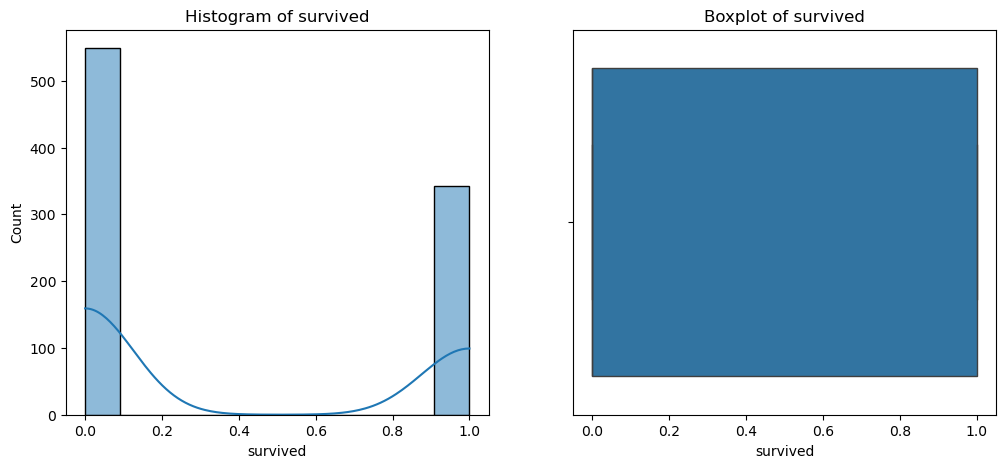

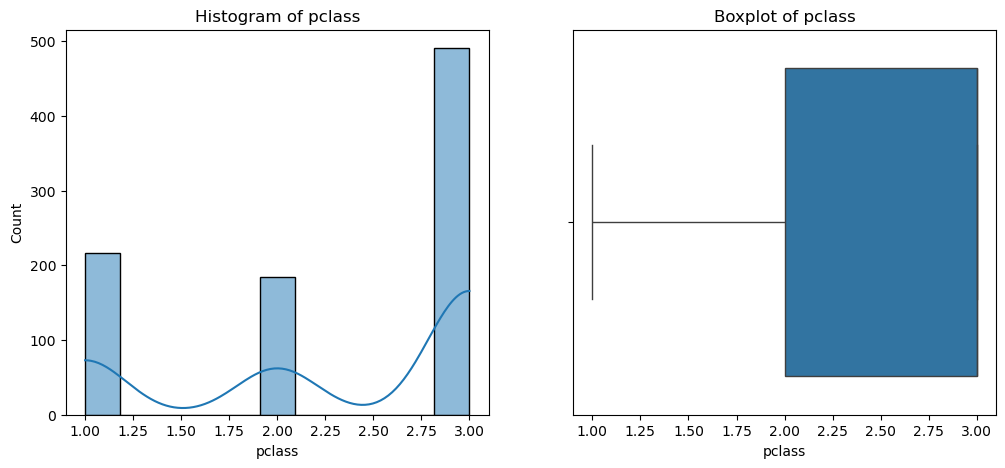

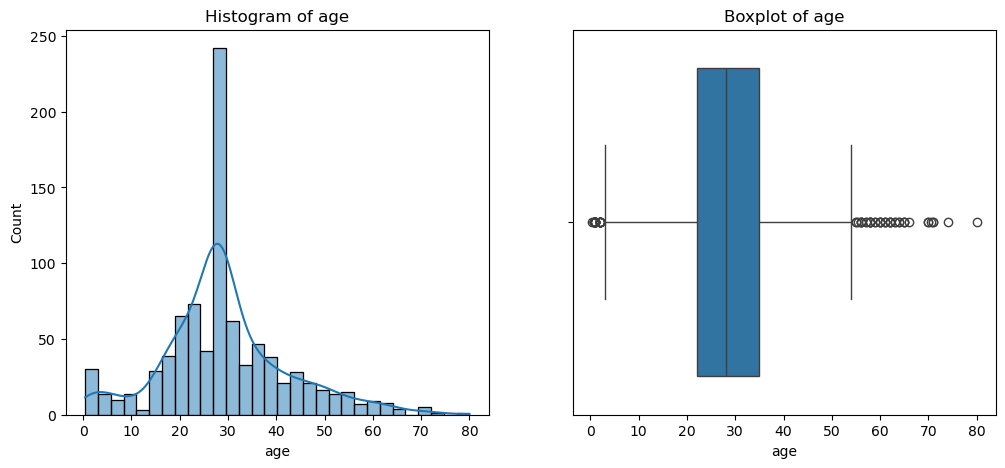

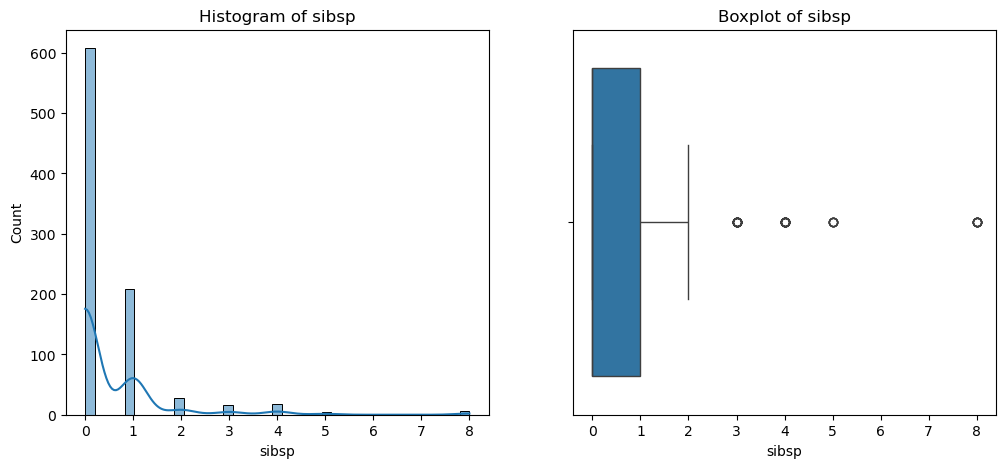

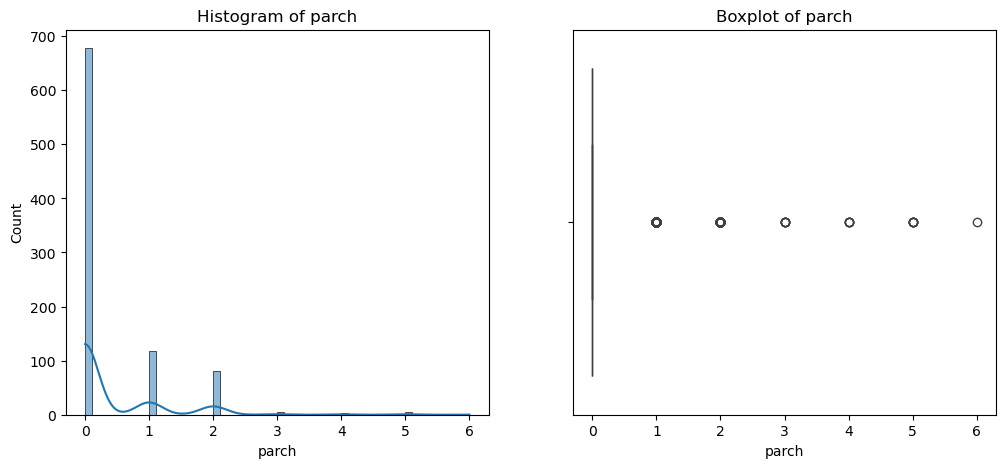

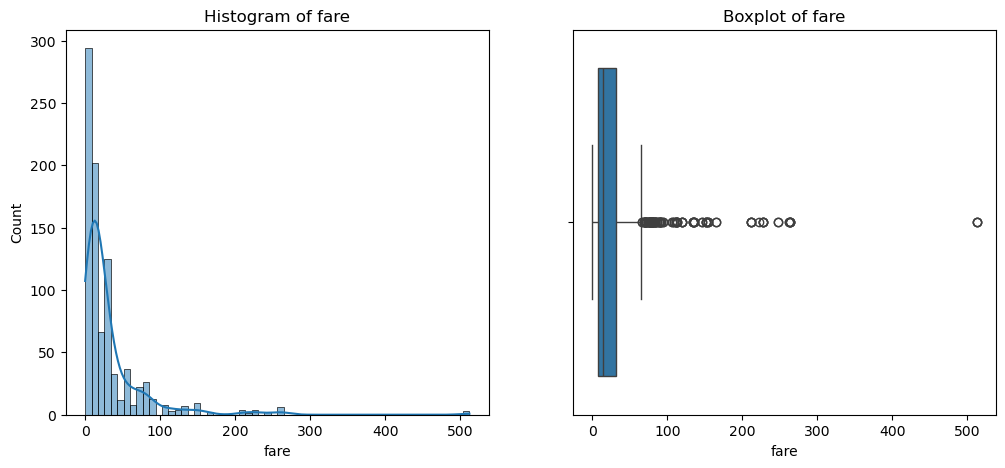

In [34]:
for column in numeric_columns:
    plt.figure(figsize=(12,5)) #Creates a new figure, 12 inches wide and 5 inches tall.
    #Histogram
    plt.subplot(1,2,1)#    Argument	Meaning
   #                            1	One row
   #                            2	Two columns
   #                            1	Select the first position

    sns.histplot(df1[column], kde=True)
    plt.title(f'Histogram of {column}')


    #Boxplot
    plt.subplot(1,2,2)
    sns.boxplot(x=df1[column])
    plt.title(f'Boxplot of {column}')


Now we need to remove the outliers

In [35]:

def remove_outliers_iqr(df1, column):
    Q1 = df1[column].quantile(0.25)  # First quartile (25%)
    Q3 = df1[column].quantile(0.75)  # Third quartile (75%)
    IQR = Q3 - Q1  # Interquartile range

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Return rows that are not outliers
    return df1[
        (df1[column] >= lower_bound) &
        (df1[column] <= upper_bound)
    ]


# Start with the original data
cleaned_data = df1.copy()

# Remove outliers for each numerical column
for column in numeric_columns:
    cleaned_data = remove_outliers_iqr(cleaned_data, column)


In [36]:
cleaned_data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,28.0,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


removed rows that are above upper bound and below lower bound

In [37]:
# checking skewness after removing outliers
cleaned_data.select_dtypes("number").skew()

survived    0.944319
pclass     -1.150755
age         0.787404
sibsp       2.245019
parch       0.000000
fare        2.021762
dtype: float64

In [38]:
cleaned_data.shape

(561, 15)

In [39]:
cleaned_data["alive"].value_counts()

alive
no     400
yes    161
Name: count, dtype: int64

In [40]:
# we need skewness between -1 and 1 so , for reducing we use sqrt
cleaned_data[numeric_columns] = np.sqrt(cleaned_data[numeric_columns])

In [42]:
cleaned_data.select_dtypes("number").skew()

survived    0.944319
pclass     -1.316597
age         0.306908
sibsp       1.840327
parch       0.000000
fare        0.758855
dtype: float64